# Regressão - Previsão do Custo de Plano de Saúde

## 1. Definição do problema

Planos de saúde precisam estimar quanto cada cliente deve custar em despesas médicas para definir o valor da mensalidade. Se o valor for baixo demais, a empresa tem prejuízo, e se for alto demais, perde clientes. Entender quais características aumentam o custo também ajuda em campanhas de prevenção, como programas para parar de fumar.

**Pergunta principal:** É possível prever o custo médico anual de uma pessoa a partir de características como idade, IMC e se ela é fumante?

**Tipo de problema:** Regressão, pois a variável alvo é um valor numérico (custo em dólares).

## 2. Apresentação da base de dados

- **Nome:** Medical Cost Personal Dataset (arquivo `insurance.csv`)
- **Origem:** base usada no livro *Machine Learning with R*, de Brett Lantz. Os dados foram simulados com base em estatísticas demográficas dos Estados Unidos. Disponível no Kaggle: https://www.kaggle.com/datasets/mirichoi0218/insurance
- **Registros:** 1.338 pessoas
- **Colunas:** 7 (6 variáveis de entrada e 1 variável alvo)

| Coluna original | Nome usado | Significado |
|---|---|---|
| age | idade | idade da pessoa |
| sex | sexo | female (feminino) ou male (masculino) |
| bmi | imc | índice de massa corporal (peso / altura²) |
| children | filhos | número de filhos cobertos pelo plano |
| smoker | fumante | yes (sim) ou no (não) |
| region | regiao | região onde mora nos EUA (northeast, northwest, southeast, southwest) |
| charges | custo | **variável alvo**: custo médico anual cobrado pelo plano (em dólares) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados
df = pd.read_csv('../dados/insurance.csv')

# renomeando as colunas para facilitar a leitura
df = df.rename(columns={
    'age': 'idade',
    'sex': 'sexo',
    'bmi': 'imc',
    'children': 'filhos',
    'smoker': 'fumante',
    'region': 'regiao',
    'charges': 'custo'
})

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 1338
Colunas: 7


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,idade,sexo,imc,filhos,fumante,regiao,custo
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# tipos de dados
df.dtypes

idade        int64
sexo           str
imc        float64
filhos       int64
fumante        str
regiao         str
custo      float64
dtype: object

In [5]:
# valores ausentes
df.isnull().sum()

idade      0
sexo       0
imc        0
filhos     0
fumante    0
regiao     0
custo      0
dtype: int64

In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicados: 1


,idade,sexo,imc,filhos,fumante,regiao,custo
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [7]:
# estatisticas basicas
df.describe().round(2)

,idade,imc,filhos,custo
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [8]:
# quantidade em cada categoria
print(df['sexo'].value_counts())
print()
print(df['fumante'].value_counts())
print()
print(df['regiao'].value_counts())

sexo
male      676
female    662
Name: count, dtype: int64

fumante
no     1064
yes     274
Name: count, dtype: int64

regiao
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


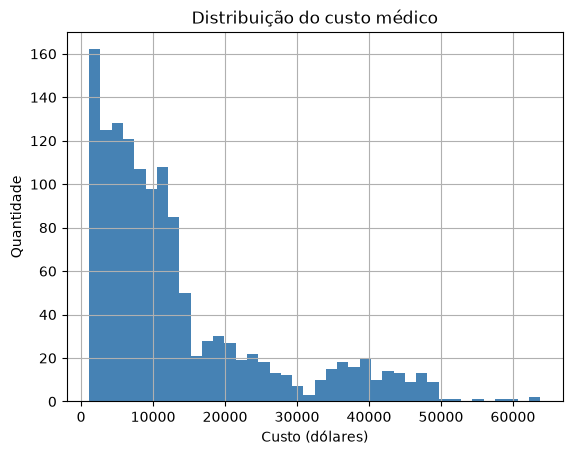

In [9]:
# distribuicao do custo
df['custo'].hist(bins=40, color='steelblue')
plt.title('Distribuição do custo médico')
plt.xlabel('Custo (dólares)')
plt.ylabel('Quantidade')
plt.show()

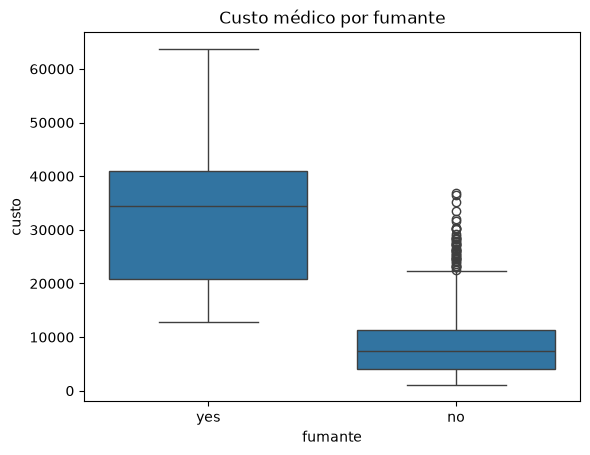

fumante
no      8434.27
yes    32050.23
Name: custo, dtype: float64


In [10]:
# custo de fumantes e nao fumantes
sns.boxplot(data=df, x='fumante', y='custo')
plt.title('Custo médico por fumante')
plt.show()

print(df.groupby('fumante')['custo'].mean().round(2))

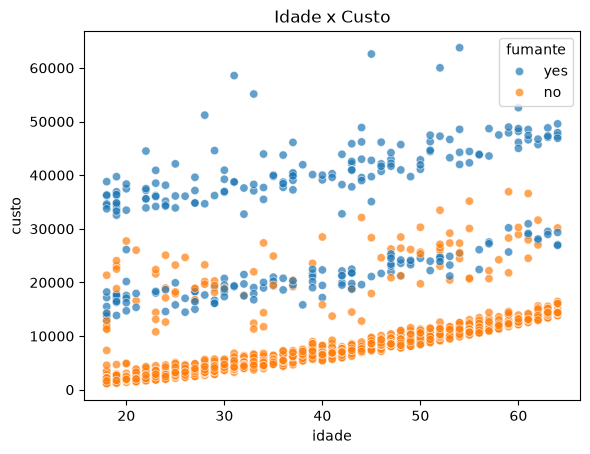

In [11]:
# idade x custo, separando fumantes
sns.scatterplot(data=df, x='idade', y='custo', hue='fumante', alpha=0.7)
plt.title('Idade x Custo')
plt.show()

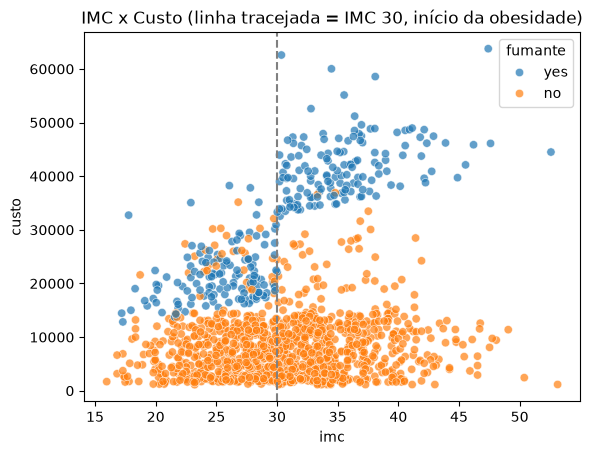

In [12]:
# imc x custo, separando fumantes
sns.scatterplot(data=df, x='imc', y='custo', hue='fumante', alpha=0.7)
plt.axvline(30, color='gray', linestyle='--')
plt.title('IMC x Custo (linha tracejada = IMC 30, início da obesidade)')
plt.show()

In [13]:
# custo medio por fumante e obesidade
df_grupos = df.copy()
df_grupos['obeso'] = np.where(df_grupos['imc'] >= 30, 'obeso', 'não obeso')
df_grupos.groupby(['fumante', 'obeso'])['custo'].mean().round(2)

fumante  obeso    
no       não obeso     7977.03
         obeso         8842.69
yes      não obeso    21363.22
         obeso        41557.99
Name: custo, dtype: float64

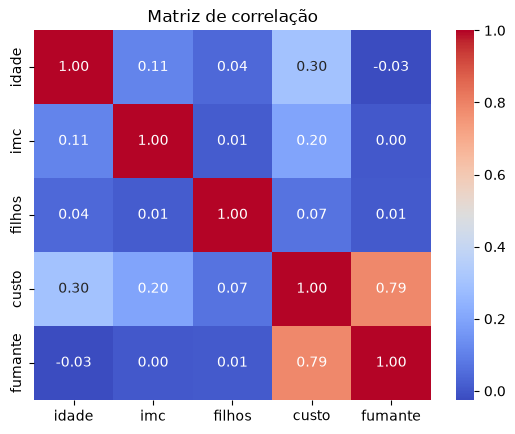

In [14]:
# matriz de correlacao (fumante convertido para 0 e 1 so para este grafico)
df_corr = df[['idade', 'imc', 'filhos', 'custo']].copy()
df_corr['fumante'] = (df['fumante'] == 'yes').astype(int)

sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlação')
plt.show()

**O que a análise mostrou:**

- A base tem 1.338 registros, nenhum valor ausente e **1 registro duplicado** (uma pessoa de 19 anos com exatamente os mesmos dados e custo).
- O custo vai de 1.122 a 63.770 dólares, com média de 13.270 e mediana de 9.382. O histograma mostra que a maioria das pessoas tem custo baixo e poucas têm custo muito alto.
- **Ser fumante é o fator mais importante** (correlação de 0,79). Os fumantes custam em média 32.050 dólares, quase 4 vezes mais que os não fumantes (8.434). Apenas 20,5% das pessoas da base são fumantes.
- A **idade** também aumenta o custo (correlação de 0,30). No gráfico de idade x custo aparecem três "faixas" separadas: não fumantes embaixo, fumantes em cima e uma faixa no meio.
- O **IMC** sozinho tem correlação fraca (0,20), mas o gráfico mostra que ele faz muita diferença **para os fumantes**: fumantes obesos (IMC 30 ou mais) custam em média 41.558, contra 21.363 dos fumantes não obesos. Para não fumantes a obesidade quase não muda o custo (8.843 contra 7.977).
- Sexo, região e número de filhos têm pouca influência no custo.

## 4. Preparação dos dados

Decisões tomadas:

1. **Valores ausentes:** a base não tem valores ausentes, então nada precisou ser preenchido.
2. **Duplicado removido:** o registro repetido foi removido. Como a base é pequena e todos os dados são iguais (inclusive o custo com várias casas decimais), é muito provável que seja a mesma pessoa registrada duas vezes.
3. **Sexo e fumante:** como só têm duas opções, foram transformados em 0 e 1 (sexo: 0 = feminino, 1 = masculino; fumante: 0 = não, 1 = sim).
4. **Região:** tem 4 categorias sem ordem entre elas, então foi usado **one-hot encoding**, criando uma coluna de 0 ou 1 para cada região.
5. **Valores altos de custo:** não foram removidos. Os custos altos são reais (principalmente de fumantes) e são justamente os casos que o modelo precisa aprender a prever.
6. **Treino e teste:** 80% treino e 20% teste.
7. **Padronização:** `StandardScaler`, porque a idade vai até 64 e o IMC até 53, enquanto as outras colunas são 0 ou 1. Isso é importante para o KNN e a Ridge.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# removendo o registro duplicado
df = df.drop_duplicates()
print('Linhas depois de remover o duplicado:', df.shape[0])

# transformando sexo e fumante em 0 e 1
df['sexo'] = (df['sexo'] == 'male').astype(int)
df['fumante'] = (df['fumante'] == 'yes').astype(int)

# one-hot encoding da regiao
df = pd.get_dummies(df, columns=['regiao'], dtype=int)

df.head()

Linhas depois de remover o duplicado: 1337


,idade,sexo,imc,filhos,fumante,custo,regiao_northeast,regiao_northwest,regiao_southeast,regiao_southwest
0,19,0,27.900,0,1,16884.92400,0,0,0,1
1,18,1,33.770,1,0,1725.55230,0,0,1,0
2,28,1,33.000,3,0,4449.46200,0,0,1,0
3,33,1,22.705,0,0,21984.47061,0,1,0,0
4,32,1,28.880,0,0,3866.85520,0,1,0,0


In [16]:
# separando entradas (X) e alvo (y)
X = df.drop(columns='custo')
y = df['custo']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# padronizando
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)
print()
print('Proporção de fumantes no treino:', round(X_treino['fumante'].mean(), 3))
print('Proporção de fumantes no teste:', round(X_teste['fumante'].mean(), 3))

Treino: (1069, 9)
Teste: (268, 9)

Proporção de fumantes no treino: 0.2
Proporção de fumantes no teste: 0.224


## 5. Escolha dos modelos

Foram usados os mesmos 5 modelos de regressão dos outros notebooks:

- **Regressão Linear:** modelo base, simples e fácil de interpretar. Cada coeficiente mostra quanto o custo aumenta para cada variável.
- **Ridge:** regressão linear com penalização, para comparar se ela ajuda em uma base pequena.
- **Árvore de Decisão Regressora:** consegue capturar combinações como "fumante e obeso", que a análise exploratória mostrou que são importantes e que uma reta não captura bem. Limitada a profundidade 5.
- **Random Forest Regressor:** média de várias árvores. Também foi limitada a profundidade 5, porque sem limite ela chegou a R² de 0,97 no treino e só 0,88 no teste, sinal de que estava decorando os dados.
- **KNN Regressor:** prevê o custo como a média das 5 pessoas mais parecidas. Foram usados 5 vizinhos porque a base é pequena.

## 6. Treinamento dos modelos

- **Dados de treino:** 1.069 pessoas (80%)
- **Dados de teste:** 268 pessoas (20%)

Cada modelo aprende com os dados de treino (`fit`) e depois prevê o custo das pessoas do teste (`predict`).

In [17]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

modelos = {
    'Regressão Linear': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(max_depth=5, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Linear - treinado
Ridge - treinado
Árvore de Decisão - treinado


Random Forest - treinado
KNN - treinado


## 7. Avaliação dos modelos

Métricas utilizadas:

- **MAE (erro absoluto médio):** em média, quantos dólares a previsão erra para mais ou para menos.
- **MSE (erro quadrático médio):** média dos erros ao quadrado. Pune mais os erros grandes.
- **RMSE (raiz do MSE):** o MSE de volta em dólares, mais fácil de interpretar.
- **R²:** quanto da variação do custo o modelo consegue explicar (quanto mais perto de 1, melhor).

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []
for nome, y_prev in previsoes.items():
    mse = mean_squared_error(y_teste, y_prev)
    resultados.append({
        'Modelo': nome,
        'MAE': mean_absolute_error(y_teste, y_prev),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R²': r2_score(y_teste, y_prev)
    })

tabela = pd.DataFrame(resultados).sort_values('R²', ascending=False)
tabela.round(3)

,Modelo,MAE,MSE,RMSE,R²
3,Random Forest,2413.283,1.798356e+07,4240.703,0.902
2,Árvore de Decisão,2598.242,1.950783e+07,4416.767,0.894
4,KNN,3474.068,2.992960e+07,5470.796,0.837
0,Regressão Linear,4177.046,3.547802e+07,5956.343,0.807
1,Ridge,4179.608,3.551207e+07,5959.200,0.807


In [19]:
# comparando o R2 no treino e no teste para ver se algum modelo decorou os dados
comparacao = []
for nome, modelo in modelos.items():
    comparacao.append({
        'Modelo': nome,
        'R² treino': r2_score(y_treino, modelo.predict(X_treino_pad)),
        'R² teste': r2_score(y_teste, previsoes[nome])
    })

pd.DataFrame(comparacao).round(3)

,Modelo,R² treino,R² teste
0,Regressão Linear,0.730,0.807
1,Ridge,0.730,0.807
2,Árvore de Decisão,0.868,0.894
3,Random Forest,0.880,0.902
4,KNN,0.850,0.837


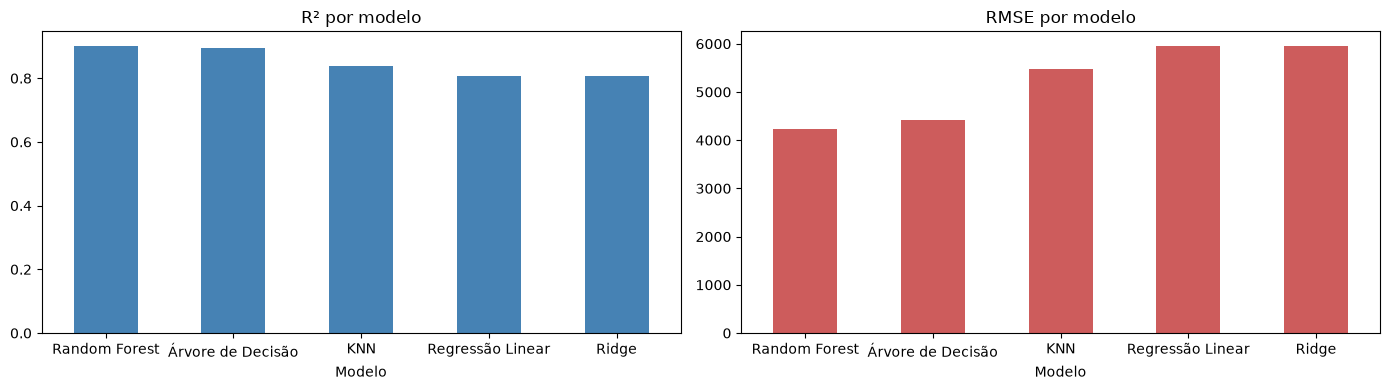

In [20]:
# comparando o R2 e o RMSE dos modelos
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
tabela.plot(x='Modelo', y='R²', kind='bar', ax=eixos[0], legend=False, color='steelblue')
eixos[0].set_title('R² por modelo')
eixos[0].tick_params(axis='x', rotation=0)
tabela.plot(x='Modelo', y='RMSE', kind='bar', ax=eixos[1], legend=False, color='indianred')
eixos[1].set_title('RMSE por modelo')
eixos[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

Melhor modelo pelo R²: Random Forest


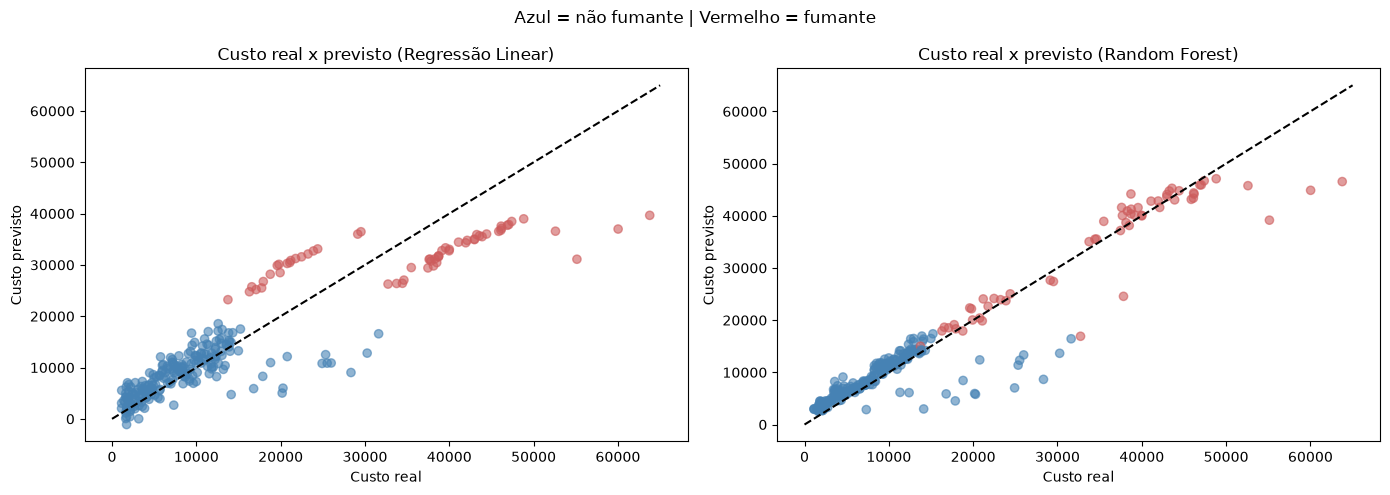

In [21]:
# valores reais x previstos: regressao linear e melhor modelo
melhor_nome = tabela.iloc[0]['Modelo']
print('Melhor modelo pelo R²:', melhor_nome)

cores = X_teste['fumante'].map({0: 'steelblue', 1: 'indianred'})

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for eixo, nome in zip(eixos, ['Regressão Linear', melhor_nome]):
    eixo.scatter(y_teste, previsoes[nome], c=cores, alpha=0.6)
    eixo.plot([0, 65000], [0, 65000], color='black', linestyle='--')
    eixo.set_title('Custo real x previsto (' + nome + ')')
    eixo.set_xlabel('Custo real')
    eixo.set_ylabel('Custo previsto')
plt.suptitle('Azul = não fumante | Vermelho = fumante')
plt.tight_layout()
plt.show()

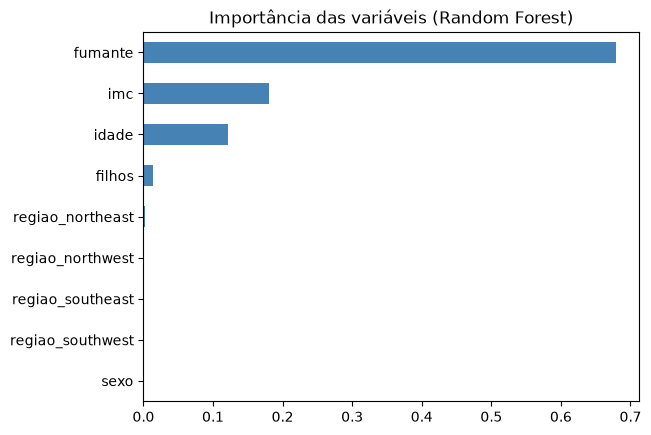

fumante             0.679
imc                 0.181
idade               0.122
filhos              0.014
regiao_northeast    0.002
regiao_northwest    0.001
regiao_southeast    0.001
regiao_southwest    0.001
sexo                0.001
dtype: float64


In [22]:
# variaveis mais importantes para o random forest
importancia = pd.Series(modelos['Random Forest'].feature_importances_, index=X.columns)
importancia.sort_values().plot(kind='barh', color='steelblue')
plt.title('Importância das variáveis (Random Forest)')
plt.show()

print(importancia.sort_values(ascending=False).round(3))

**Interpretação dos resultados:**

- O melhor modelo foi o **Random Forest**, com R² de 0,902. Ele explica cerca de 90% da variação do custo médico. A Árvore de Decisão ficou logo atrás (0,894).
- O **MAE** do Random Forest foi de 2.413 dólares. Como o custo médio no teste é de cerca de 14.270, o erro médio fica perto de 17% do valor.
- A **Regressão Linear** e a **Ridge** foram as piores (R² de 0,807). Elas erram muito mais nos fumantes: o erro médio da Regressão Linear nos fumantes é de cerca de 9.050 dólares, contra cerca de 2.700 do Random Forest. Ela chegou a prever um custo negativo para uma pessoa, o que é impossível.
- Isso acontece porque a Regressão Linear soma o efeito de cada variável separadamente, mas, como visto na análise exploratória, o IMC só aumenta muito o custo **quando a pessoa também é fumante**. As árvores conseguem criar regras do tipo "se fumante e IMC acima de 30", por isso foram melhores.
- No gráfico de real x previsto, os pontos vermelhos (fumantes) ficam bem espalhados na Regressão Linear, enquanto no Random Forest eles ficam mais perto da linha.
- Na tabela de treino x teste, nenhum modelo ficou com o teste muito abaixo do treino, então não há sinal de overfitting. Na Regressão Linear o teste ficou até um pouco melhor que o treino (0,807 contra 0,730), o que pode acontecer por acaso em uma base pequena, dependendo de quais pessoas caíram no teste.
- Pela importância do Random Forest, **ser fumante** responde por 68% das decisões do modelo, seguido de **IMC** (18%) e **idade** (12%). Sexo e região quase não influenciam.

## 8. Exemplo de previsão

Usando o melhor modelo para prever o custo de 4 pessoas novas (valores inventados). Todas têm 40 anos, são do sexo masculino, sem filhos e moram na região southeast. A única diferença é se fumam e o IMC, para ver como o modelo reage a essas duas variáveis.

In [23]:
novas_pessoas = pd.DataFrame({
    'idade': [40, 40, 40, 40],
    'sexo': [1, 1, 1, 1],
    'imc': [25.0, 35.0, 25.0, 35.0],
    'filhos': [0, 0, 0, 0],
    'fumante': [0, 0, 1, 1],
    'regiao_northeast': [0, 0, 0, 0],
    'regiao_northwest': [0, 0, 0, 0],
    'regiao_southeast': [1, 1, 1, 1],
    'regiao_southwest': [0, 0, 0, 0]
})

melhor_modelo = modelos[melhor_nome]
novas_pad = scaler.transform(novas_pessoas)

resultado = novas_pessoas[['idade', 'imc', 'fumante']].copy()
resultado['custo_previsto'] = melhor_modelo.predict(novas_pad).round(2)
resultado

,idade,imc,fumante,custo_previsto
0,40,25.0,0,7060.99
1,40,35.0,0,6850.35
2,40,25.0,1,20114.43
3,40,35.0,1,39112.04


O resultado mostra bem o que a análise encontrou:

- Para quem **não fuma**, passar de IMC 25 para 35 praticamente não muda o custo previsto (cerca de 7 mil nos dois casos).
- Só por **fumar**, o custo previsto sobe de cerca de 7 mil para cerca de 20 mil, quase 3 vezes mais.
- O fumante com **IMC 35** tem o maior custo previsto (cerca de 39 mil), quase o dobro do fumante com IMC 25. Ou seja, o modelo aprendeu que a obesidade pesa muito mais para quem fuma.

## 9. Conclusão

**Resumo:** o objetivo foi prever o custo médico anual de uma pessoa usando idade, sexo, IMC, número de filhos, se é fumante e a região onde mora. Foram testados 5 modelos de regressão em 1.337 registros.

**Principais descobertas:** ser fumante é de longe o fator que mais aumenta o custo, e os fumantes custam em média quase 4 vezes mais. A idade também aumenta o custo de forma constante. O IMC só faz grande diferença quando a pessoa também é fumante, uma combinação que os modelos de árvore conseguiram aprender, mas a regressão linear não. Sexo e região quase não influenciam.

**Desempenho:** o melhor modelo foi o Random Forest com profundidade limitada, com R² de 0,902 e erro médio de cerca de 2.400 dólares. A resposta para a pergunta é **sim, é possível prever o custo médico com boa precisão** usando poucas informações.

**Limitações:**
- Os dados são **simulados** com base em estatísticas dos Estados Unidos e não são clientes reais, então o resultado pode ser diferente em uma base real.
- A base é pequena (1.337 pessoas) e tem poucas colunas. Faltam informações importantes, como histórico de doenças, uso de medicamentos e prática de exercícios.
- O custo depende muito do sistema de saúde dos EUA e não pode ser aplicado diretamente ao Brasil.
- Mesmo o melhor modelo ainda erra bastante em algumas pessoas (RMSE de 4.240, bem maior que o MAE).

**Melhorias futuras:**
- Criar uma nova coluna que combine fumante e obesidade, o que deve ajudar principalmente a Regressão Linear.
- Ajustar os hiperparâmetros com `GridSearchCV` e usar validação cruzada, já que a base é pequena.
- Testar modelos como o Gradient Boosting.
- Usar uma base real e com mais variáveis de saúde.

**Opinião crítica:** o Machine Learning funcionou bem neste problema e mostrou de forma clara o impacto do cigarro no custo com saúde, o que pode ser útil em campanhas de prevenção. Por outro lado, usar um modelo assim para definir o preço do plano levanta questões éticas: pessoas com mais risco poderiam pagar valores muito altos ou ficar sem acesso ao plano. Por isso, um modelo desse tipo deve ser usado com cuidado e respeitando as regras do setor. No Brasil, por exemplo, a ANS limita quais critérios os planos podem usar para variar o preço.